In [2]:
from openfermion.ops import QubitOperator
import numpy as np
from tqdm import tqdm
import pandas as pd
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import networkx as nx

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [3]:
from qiskit.circuit.library import TwoLocal, RealAmplitudes, EfficientSU2
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit import Parameter
from qiskit_algorithms import NumPyMinimumEigensolver
# from qiskit import execute, Aer
from qiskit.primitives import BackendSampler
from qiskit.primitives import Sampler
from qiskit.providers.options import Options
# from qiskit.providers.aer import AerSimulator
from qiskit_algorithms.optimizers import SLSQP,COBYLA,ADAM, SPSA, QNSPSA,NFT
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import TwoLocal

In [4]:
from qiskit_algorithms import SamplingVQE
from qiskit_aer import AerSimulator

In [6]:
import matplotlib as mpl
import os

# Set TEX environment variable
# os.environ['TEX'] = '/home/himashu/.TinyTeX'

# Add TinyTeX bin directory to PATH
# os.environ['PATH'] = '/home/himashu/.TinyTeX/bin/x86_64-linux:' + os.environ['PATH']

# Configure matplotlib to use LaTeX
# mpl.rcParams['text.usetex'] = True
# plt.rcParams['font.family'] = 'comfortaa'
plt.rcParams['text.color'] = 'k'
plt.rcParams['axes.labelcolor'] = 'k'
# plt.style.use('seaborn')
# plt.style.use('default')

In [7]:
adjacency_matrix = np.array([[0.,5.,3.,0.,0.,0.,0.,0.,0.,0.,0.],
 [0.,0.,5.,4.,0.,0.,0.,0.,0.,0.,0.],
 [0.,0.,0.,6.,4.,0.,0.,0.,0.,0.,0.],
 [0.,0.,0.,0.,5.,0.,0.,0.,0.,0.,0.],
 [0.,0.,0.,0.,0.,3.,0.,3.,0.,0.,0.],
 [0.,0.,0.,0.,0.,0.,6.,0.,0.,0.,0.],
 [0.,0.,0.,0.,0.,0.,0.,0.,0.,0.,0.],
 [0.,0.,0.,0.,0.,0.,0.,0.,6.,4.,0.],
 [0.,0.,0.,0.,0.,0.,0.,0.,0.,5.,3.],
 [0.,0.,0.,0.,0.,0.,0.,0.,0.,0.,5.],
 [0.,0.,0.,0.,0.,3.,0.,3.,0.,0.,0.]],dtype = float)

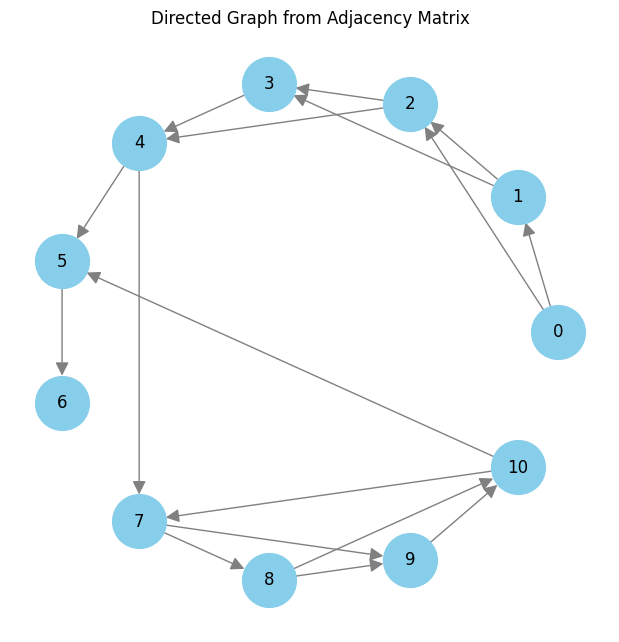

In [10]:
# Create a directed graph from the adjacency matrix
G = nx.from_numpy_array(adjacency_matrix, create_using=nx.DiGraph)

# Draw the graph
plt.figure(figsize=(6, 6))
pos = nx.circular_layout(G)  # positions for all nodes
nx.draw(G, pos, with_labels=True, node_color='skyblue', node_size=1500, edge_color='gray', arrowsize=20)
plt.title('Directed Graph from Adjacency Matrix')
# plt.savefig('graph.jpg')
plt.show()

In [9]:
W = -5*np.array(adjacency_matrix,dtype = float)
num_pos = W.shape[0]
α = 1*np.max(abs(W))/5

for i in range(len(W)):
    for j in range(len(W)):
        if W[i,j] == 0:
            W[i,j] = α # + np.random.uniform()


node = W.shape[0]
node_qubit = int(np.ceil(np.log2(node)))
num_qubits = node_qubit*num_pos
print('Number of qubits for nodes :', node_qubit)
print('Number of positions : ',num_pos)
print('Number of qubits required:', num_qubits)

print(pd.DataFrame(W))

Number of qubits for nodes : 4
Number of positions :  11
Number of qubits required: 44
     0     1     2     3     4     5     6     7     8     9     10
0   6.0 -25.0 -15.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0
1   6.0   6.0 -25.0 -20.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0
2   6.0   6.0   6.0 -30.0 -20.0   6.0   6.0   6.0   6.0   6.0   6.0
3   6.0   6.0   6.0   6.0 -25.0   6.0   6.0   6.0   6.0   6.0   6.0
4   6.0   6.0   6.0   6.0   6.0 -15.0   6.0 -15.0   6.0   6.0   6.0
5   6.0   6.0   6.0   6.0   6.0   6.0 -30.0   6.0   6.0   6.0   6.0
6   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0
7   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0 -30.0 -20.0   6.0
8   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0 -25.0 -15.0
9   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0   6.0 -25.0
10  6.0   6.0   6.0   6.0   6.0 -15.0   6.0 -15.0   6.0   6.0   6.0


In [13]:
def P0(i):
    iden = QubitOperator('')
    Z = QubitOperator('Z' + str(i))
    return 0.5*(iden + Z)


def P1(i):
    iden = QubitOperator('')
    Z = QubitOperator('Z' + str(i))
    return 0.5*(iden - Z)


def number_to_fixed_length_binary_array(number, length):
    binary_string = bin(number)[2:]  # Get binary representation as a string, removing the '0b' prefix
    padded_binary_string = binary_string.zfill(length)  # Pad with leading zeros to ensure fixed length
    binary_array = np.array([int(bit) for bit in padded_binary_string])  # Convert binary string to numpy array
    return binary_array

def occupation_op(num,pos,N):

    # num : node number
    # N : total qubit for node
    # pos : position runs from 0 to edge - 1

    Ait = QubitOperator('')

    binary_array = number_to_fixed_length_binary_array(num, N)
    Nbit = len(binary_array)
    for i in range(Nbit):
        if binary_array[i] == 1:
            Ait = Ait*P1(i + pos*Nbit)
        else:
            Ait = Ait*P0(i + pos*Nbit)

    return Ait


bit = []

for ti in (range(num_pos)):
    bi = []
    for i in range(node):
        bi.append(occupation_op(i,ti,node_qubit))
    bit.append(bi)

In [14]:
# Visit Once

identity = QubitOperator('')

H1 = 0

A2 = 1.5*np.max(W)

for i in range(node):
    term = 0
    for t in range(num_pos):
        term += bit[t][i]
    term_sq = (identity-term)*(identity-term)
    H1 += term_sq

# Visit once version 02

# H1 = 0

# for t in range(num_pos):
#     for tdash in range(t+1,num_pos):
#         for i in range(node):
#             H1 += 2*bit[t][i]*bit[tdash][i] - (1/(node-1))*(bit[t][i] + bit[tdash][i] + 2)


# including weights

H2 = 0

for t in tqdm(range(num_pos - 1)):
    for i in range(node):
        for j in range(node):
            H2 += W[i,j]*(bit[t][i]*bit[t+1][j])

B = 1

H = A2*H1 + B*H2

100%|██████████| 10/10 [00:05<00:00,  1.97it/s]


In [36]:
H_op = H.terms

print('Constructing Hamiltonian...Completed.')

print('Initiating VQE..')

op = []

for key, value in H_op.items():
    strlist = ['I' for i in range(num_qubits)]
    for item in key:
        strlist[item[0]] = 'Z'
    op_string = ''.join(strlist)
    op.append((op_string,value))

# op.pop(0)

print(pd.DataFrame(op))

Hop = SparsePauliOp.from_list(op)

Constructing Hamiltonian...Completed.
Initiating VQE..
                                                  0          1
0      IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII  83.593750
1      ZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII   1.144531
2      IIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII   1.742188
3      IIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII   1.742188
4      IIIIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII   1.742188
...                                             ...        ...
12536  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZZZIZZI  -0.167969
12537  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZZZZIII  -0.277344
12538  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZZZZIZI  -0.636719
12539  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZZZZZII  -0.144531
12540  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZZZZZZI  -0.878906

[12541 rows x 2 columns]


In [37]:
## search for source node :

for i in range(adjacency_matrix.shape[0]):
    x = np.sum(adjacency_matrix[:,i])
    if x == 0:
        print('source point -- ', i)
        source_node = i
        break


source point --  0


In [38]:
## end node :

for i in range(adjacency_matrix.shape[0]):
    x = np.sum(adjacency_matrix[i,:])
    if x == 0:
        print('end point -- ', i)
        end_node = i
        break

end point --  6


In [39]:
print('source node : ', source_node,' & end node : ', end_node)

source node :  0  & end node :  6


In [40]:
ref = QuantumCircuit(num_qubits)

source_bit = number_to_fixed_length_binary_array(source_node,node_qubit)
end_bit = number_to_fixed_length_binary_array(end_node,node_qubit)
print(source_bit, end_bit)

[0 0 0 0] [0 1 1 0]


In [41]:
ref = QuantumCircuit(num_qubits)

source_bit = number_to_fixed_length_binary_array(source_node,node_qubit)
end_bit = number_to_fixed_length_binary_array(end_node,node_qubit)

for i in range(node_qubit):
    if source_bit[i] == 1:
        ref.x(num_qubits-1-i)
    if end_bit[i] == 1:
        ref.x(i)

ref.draw()

q_0: ─────
      ┌───┐
 q_1: ┤ X ├
      ├───┤
 q_2: ┤ X ├
      └───┘
 q_3: ─────
           
 q_4: ─────
           
 q_5: ─────
           
 q_6: ─────
           
 q_7: ─────
           
 q_8: ─────
           
 q_9: ─────
           
q_10: ─────
           
q_11: ─────
           
q_12: ─────
           
q_13: ─────
           
q_14: ─────
           
q_15: ─────
           
q_16: ─────
           
q_17: ─────
           
q_18: ─────
           
q_19: ─────
           
q_20: ─────
           
q_21: ─────
           
q_22: ─────
           
q_23: ─────
           
q_24: ─────
           
q_25: ─────
           
q_26: ─────
           
q_27: ─────
           
q_28: ─────
           
q_29: ─────
           
q_30: ─────
           
q_31: ─────
           
q_32: ─────
           
q_33: ─────
           
q_34: ─────
           
q_35: ─────
           
q_36: ─────
           
q_37: ─────
           
q_38: ─────
           
q_39: ─────
           
q_40: ─────
           
q_41: ─────
           
q_42: ─────
           
q_43: ─────

In [42]:
ansatz = QuantumCircuit(num_qubits)

for i in range(num_pos-2):
    ansatz.append(EfficientSU2(node_qubit,su2_gates=["rx", "ry"], reps=1, parameter_prefix='φ' + str(i) , insert_barriers=True).decompose(), range(node_qubit + i*node_qubit,node_qubit + (i+1)*node_qubit))

ansatz = ref.compose(ansatz)

ansatz.decompose().draw()

»
 q_0: ─────────────────────────────────────────────────────────────»
      ┌───────────┐                                                »
 q_1: ┤ U3(π,0,π) ├────────────────────────────────────────────────»
      ├───────────┤                                                »
 q_2: ┤ U3(π,0,π) ├────────────────────────────────────────────────»
      └───────────┘                                                »
 q_3: ─────────────────────────────────────────────────────────────»
      ┌───────────┐┌───────────┐ ░                 ░ ┌───────────┐ »
 q_4: ┤ Rx(φ0[0]) ├┤ Ry(φ0[4]) ├─░─────────────■───░─┤ Rx(φ0[8]) ├─»
      ├───────────┤├───────────┤ ░           ┌─┴─┐ ░ ├───────────┤ »
 q_5: ┤ Rx(φ0[1]) ├┤ Ry(φ0[5]) ├─░────────■──┤ X ├─░─┤ Rx(φ0[9]) ├─»
      ├───────────┤├───────────┤ ░      ┌─┴─┐└───┘ ░ ├───────────┴┐»
 q_6: ┤ Rx(φ0[2]) ├┤ Ry(φ0[6]) ├─░───■──┤ X ├──────░─┤ Rx(φ0[10]) ├»
      ├───────────┤├───────────┤ ░ ┌─┴─┐└───┘      ░ ├────────────┤»
 q_7: ┤ Rx(φ0[3]) ├┤ Ry(φ0[7]) ├─░─┤ X ├───────────░─┤ Rx(φ0[11]) ├»
      ├───────────┤├───────────┤ ░ └───┘           ░ ├───────────┬┘»
 q_8: ┤ Rx(φ1[0]) ├┤ Ry(φ1[4]) ├─░─────────────■───░─┤ Rx(φ1[8]) ├─»
      ├───────────┤├───────────┤ ░           ┌─┴─┐ ░ ├───────────┤ »
 q_9: ┤ Rx(φ1[1]) ├┤ Ry(φ1[5]) ├─░────────■──┤ X ├─░─┤ Rx(φ1[9]) ├─»
      ├───────────┤├───────────┤ ░      ┌─┴─┐└───┘ ░ ├───────────┴┐»
q_10: ┤ Rx(φ1[2]) ├┤ Ry(φ1[6]) ├─░───■──┤ X ├──────░─┤ Rx(φ1[10]) ├»
      ├───────────┤├───────────┤ ░ ┌─┴─┐└───┘      ░ ├────────────┤»
q_11: ┤ Rx(φ1[3]) ├┤ Ry(φ1[7]) ├─░─┤ X ├───────────░─┤ Rx(φ1[11]) ├»
      ├───────────┤├───────────┤ ░ └───┘           ░ ├───────────┬┘»
q_12: ┤ Rx(φ2[0]) ├┤ Ry(φ2[4]) ├─░─────────────■───░─┤ Rx(φ2[8]) ├─»
      ├───────────┤├───────────┤ ░           ┌─┴─┐ ░ ├───────────┤ »
q_13: ┤ Rx(φ2[1]) ├┤ Ry(φ2[5]) ├─░────────■──┤ X ├─░─┤ Rx(φ2[9]) ├─»
      ├───────────┤├───────────┤ ░      ┌─┴─┐└───┘ ░ ├───────────┴┐»
q_14: ┤ Rx(φ2[2]) ├┤ Ry(φ2[6]) ├─░───■──┤ X ├──────░─┤ Rx(φ2[10]) ├»
      ├───────────┤├───────────┤ ░ ┌─┴─┐└───┘      ░ ├────────────┤»
q_15: ┤ Rx(φ2[3]) ├┤ Ry(φ2[7]) ├─░─┤ X ├───────────░─┤ Rx(φ2[11]) ├»
      ├───────────┤├───────────┤ ░ └───┘           ░ ├───────────┬┘»
q_16: ┤ Rx(φ3[0]) ├┤ Ry(φ3[4]) ├─░─────────────■───░─┤ Rx(φ3[8]) ├─»
      ├───────────┤├───────────┤ ░           ┌─┴─┐ ░ ├───────────┤ »
q_17: ┤ Rx(φ3[1]) ├┤ Ry(φ3[5]) ├─░────────■──┤ X ├─░─┤ Rx(φ3[9]) ├─»
      ├───────────┤├───────────┤ ░      ┌─┴─┐└───┘ ░ ├───────────┴┐»
q_18: ┤ Rx(φ3[2]) ├┤ Ry(φ3[6]) ├─░───■──┤ X ├──────░─┤ Rx(φ3[10]) ├»
      ├───────────┤├───────────┤ ░ ┌─┴─┐└───┘      ░ ├────────────┤»
q_19: ┤ Rx(φ3[3]) ├┤ Ry(φ3[7]) ├─░─┤ X ├───────────░─┤ Rx(φ3[11]) ├»
      ├───────────┤├───────────┤ ░ └───┘           ░ ├───────────┬┘»
q_20: ┤ Rx(φ4[0]) ├┤ Ry(φ4[4]) ├─░─────────────■───░─┤ Rx(φ4[8]) ├─»
      ├───────────┤├───────────┤ ░           ┌─┴─┐ ░ ├───────────┤ »
q_21: ┤ Rx(φ4[1]) ├┤ Ry(φ4[5]) ├─░────────■──┤ X ├─░─┤ Rx(φ4[9]) ├─»
      ├───────────┤├───────────┤ ░      ┌─┴─┐└───┘ ░ ├───────────┴┐»
q_22: ┤ Rx(φ4[2]) ├┤ Ry(φ4[6]) ├─░───■──┤ X ├──────░─┤ Rx(φ4[10]) ├»
      ├───────────┤├───────────┤ ░ ┌─┴─┐└───┘      ░ ├────────────┤»
q_23: ┤ Rx(φ4[3]) ├┤ Ry(φ4[7]) ├─░─┤ X ├───────────░─┤ Rx(φ4[11]) ├»
      ├───────────┤├───────────┤ ░ └───┘           ░ ├───────────┬┘»
q_24: ┤ Rx(φ5[0]) ├┤ Ry(φ5[4]) ├─░─────────────■───░─┤ Rx(φ5[8]) ├─»
      ├───────────┤├───────────┤ ░           ┌─┴─┐ ░ ├───────────┤ »
q_25: ┤ Rx(φ5[1]) ├┤ Ry(φ5[5]) ├─░────────■──┤ X ├─░─┤ Rx(φ5[9]) ├─»
      ├───────────┤├───────────┤ ░      ┌─┴─┐└───┘ ░ ├───────────┴┐»
q_26: ┤ Rx(φ5[2]) ├┤ Ry(φ5[6]) ├─░───■──┤ X ├──────░─┤ Rx(φ5[10]) ├»
      ├───────────┤├───────────┤ ░ ┌─┴─┐└───┘      ░ ├────────────┤»
q_27: ┤ Rx(φ5[3]) ├┤ Ry(φ5[7]) ├─░─┤ X ├───────────░─┤ Rx(φ5[11]) ├»
      ├───────────┤├───────────┤ ░ └───┘           ░ ├───────────┬┘»
q_28: ┤ Rx(φ6[0]) ├┤ Ry(φ6[4]) ├─░─────────────■───░─┤ Rx(φ6[8]) ├─»
      ├───────────┤├───────────┤ ░           ┌─┴─┐ ░ ├───────────

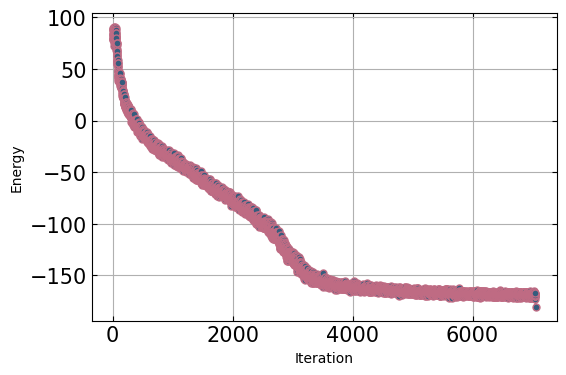

00000001001000110100011110001001101001010110


In [43]:
Hop = SparsePauliOp.from_list(op)


## Optimizer : SPSA
# backend = Aer.get_backend('qasm_simulator')
# backend = AerSimulator(method = 'matrix_product_state')
backend = AerSimulator(method = 'matrix_product_state')

# backend = QasmSimulator(method='matrix_product_state')
options = Options()
options.shots = int(2**12) # 4000
sampler = BackendSampler(backend=backend)

# set classical optimizer
optimizer = SPSA(maxiter = 3500)
# optimizer = NFT(maxiter=3000) # SPSA()
# optimizer = NFT(maxiter=1000) # SPSA()

# optimizer = SPSA(
#     maxiter=1000,
#     blocking=True,
#     allowed_increase=0.01,
#     # trust_region=True,
#     # learning_rate=lambda k: 0.1 / (k + 1)**0.6,
#     # perturbation=lambda k: 0.1 / (k + 1)**0.101,
#     # last_avg=10,
#     # resamplings=5,
#     perturbation_dims=None,  # Perturb all dimensions
#     # second_order=True,
#     # regularization=lambda x: 0.01 * sum(x**2),  # Example regularization term
#     # hessian_delay=5,
#     lse_solver=None,  # Default least-squares solver
#     initial_hessian=None,  # No initial Hessian
#     # callback=lambda n, x, fx: print(f"Iteration {n}, x={x}, f(x)={fx}")
# )

counts = []
values = []
params = []

# Function to plot energy after each iteration
def plot_energy(counts, values):
    fig, ax = plt.subplots(figsize = (6,4))
    ax.plot(counts, values, marker='o', linestyle='-',color = '#C06C84',markerfacecolor='#355C7D',markersize = 5)
    plt.tick_params(top=True, left=True, right=True, bottom=True,direction="in",axis='both', which='both', labelsize=15)
    font2 = {'family':'comfortaa','color':'black','size':18}
    # ax.set_xlabel('Iteration',fontdict = font2)
    ax.set_xlabel('Iteration')
    # ax.set_ylabel('Energy',fontdict = font2)
    ax.set_ylabel('Energy')
    # plt.title('Energy vs Iteration')
    ax.grid(zorder=0)
    plt.show()


def store_intermediate_result(eval_count, parameters, mean, std):
    counts.append(eval_count)
    values.append(np.real(mean))
    # print(eval_count, "energy_exp = ", np.real(mean))
    params.append(parameters)
    # Plot energy after each iteration
    clear_output(wait=True)
    plot_energy(counts, values)

# initialize VQE using CVaR with alpha = 0.1

vqe = SamplingVQE(
    sampler,
    ansatz=ansatz,
    optimizer=optimizer,
#     aggregation=0.1,
#     initial_point = params,
    callback=store_intermediate_result,
    )

# Estimator approach

# vqe = VQE(
#     sampler,
#     ansatz=ansatz,
#     optimizer=optimizer,
# #     aggregation=0.1,
# #     initial_point = params,
#     callback=store_intermediate_result,
#     )

raw_result = vqe.compute_minimum_eigenvalue(Hop)
print(raw_result.best_measurement['bitstring'])

# np.savetxt('energy.txt',np.array(values))

val = raw_result.best_measurement['bitstring']


In [44]:
def violations(val):

    vio = 0
    num_seq = []

    for i in range(num_pos):
        num_seq.append(int(val[i*node_qubit:node_qubit*i+node_qubit],2))

    for i in range(num_pos-1):
        if adjacency_matrix[num_seq[i],num_seq[i+1]] == 0:
            vio +=1
            print(num_seq[i],num_seq[i+1])

    return vio,num_seq

vio,num_seq = violations(val)

print('No of violations ',vio)

No of violations  0


In [46]:
num_seq

[0, 1, 2, 3, 4, 7, 8, 9, 10, 5, 6]

In [11]:
def list_of_all_connected_nodes(adjacency_mat:np.ndarray) -> list:

    """
    Takes adjacency matrix as input and
    returns list of all connected nodes corresponding to every edge
    Useful to assess solutions
    """

    connected_nodes = [[i,j] for i in range(0,num_pos) for j in range (0,num_pos)
                        if adjacency_matrix[i][j]!=0]
    return connected_nodes

def connection_nodes(node:int, adjacency_mat:np.ndarray) -> list:

    """
    Takes a node and adjacency matrix as the input
    and returns list of nodes that have edges connecting them
    """

    connection_nodess = [j for j in range(0,num_pos) if adjacency_matrix[node][j]!=0]
    return connection_nodess

def violations(sol,adjacency_mat):

    """
    Takes solution and the adjacency matrix as inputs
    Returns list of nodes where violations are found
    """

    violation_sites = []
    for i in range(0,len(sol)-1):
        if sol[i+1] not in connection_nodes(sol[i],adjacency_mat):
            violation_sites.append(sol[i])
            print('Violation at Node',sol[i],'(Position',i,
                  '). Edge',[sol[i],sol[i+1]],
                  'is not among', [[sol[i],j] for j in connection_nodes(sol[i],adjacency_mat)])
    return violation_sites

def repetitions(sol):

    """
    Takes solution candidate as the input
    Returns a list of the nodes in the solution that are repeated along the path
    and their frequency
    """

    sol_set = list(set(sol))
    counts = [[i,sol.count(i)] for i in sol_set if sol.count(i)>1]
    [print('Node',counts[i][0],'repeated',counts[i][1],'times.') for i in range(0,len(counts))]
    return counts

def check_missing_nodes(sol,adjacency_mat):

    """
    Checks if there are any nodes missing in the path
    Takes the solution candidate and adjacency matrix as the input
    Returns a list of the missing nodes if they exist, else None
    """

    missing_nodes = [i for i in range(0,len(adjacency_mat)) if i not in sol]
    if missing_nodes == []:
        print('No missing nodes in Solution')
        return None
    else:
        print('Solution missing node(s)',missing_nodes)
        return missing_nodes

def solution_quality_check(sol,adjacency_mat):

    """
    Checks the quality of solution by evaluating possible violations, repetitions,
    and missing nodes
    Takes solution candidate and adjacency matrix as the input
    Returns a dictionary with stats of violations, repetitions, and missing nodes
    """

    violation_counts = violations(sol,adjacency_mat)
    repetition_counts = repetitions(sol)
    missing_nodes = check_missing_nodes(sol,adjacency_mat)
    answer = {
            'violation_counts':[len(violation_counts),violation_counts],
            'repetition_counts':repetition_counts,
            'missing_nodes': missing_nodes
            }
    return answer

In [ ]:
sol = [0, 1, 2, 3, 4, 7, 8, 9, 10, 5, 6]
solution_quality_check(sol,adjacency_matrix)


No missing nodes in Solution


{'violation_counts': [0, []], 'repetition_counts': [], 'missing_nodes': None}

In [ ]:
## End of file